# Do citation communities follow arXiv subject categories?

ogbn-arxiv citation graph: 169,343 arXiv CS papers, 1,166,243 citations, 40 subject categories.

**Research question.** Do the communities formed by citations follow the official arXiv categories, which influential papers act as bridges between communities, and what hidden patterns does the citation graph show?

**Contents**
1. Setup
2. Data: download, load, preparation and the citation graph
3. RQ1 Influence: does PageRank tell us more than citation counts?
4. RQ2 Alignment: do Louvain communities match the arXiv categories? (incl. what communities are grouped by)
5. RQ3 Bridges: which influential papers connect communities?
6. Robustness check: citations to a newer paper (RQ1 and RQ2)
7. Saved results

**Running.** Restart and run all. Data is downloaded to `data/` on the first run (skipped if present); outputs go to `results/`. Slow cell: the Louvain resolution sweep (~40 min, 30 runs). All seeds are fixed (Louvain 42-47, sampling 42).

# 1. Setup

In [ ]:
import csv
import os
import pathlib
import random
import tarfile
import unicodedata
import urllib
import zipfile
from collections import Counter, defaultdict
from itertools import combinations

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.stats import spearmanr
from networkx.algorithms.community import louvain_communities
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

In [ ]:
DATA_DIR = pathlib.Path("data")
DATASET_ZIP_PATH = DATA_DIR / "arxiv.zip"
DATASET_DIR = DATA_DIR / "ogbn_arxiv"
PAPER_ZIP_PATH = DATA_DIR / "titleabs.tsv.gz"
PAPER_CSV_PATH = DATA_DIR / "titleabs.csv"


# 2. Data
## 2.1 Download

In [ ]:
os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(DATASET_DIR):
    urllib.request.urlretrieve("http://snap.stanford.edu/ogb/data/nodeproppred/arxiv.zip", DATASET_ZIP_PATH)
    with zipfile.ZipFile(DATASET_ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)


In [ ]:
if not os.path.exists(PAPER_CSV_PATH):
    urllib.request.urlretrieve("https://snap.stanford.edu/ogb/data/misc/ogbn_arxiv/titleabs.tsv.gz", PAPER_ZIP_PATH)
    with tarfile.open(PAPER_ZIP_PATH, "r:*") as tar:
        member = tar.getmembers()[0]
        titles = pd.read_csv(
            tar.extractfile(member),
            sep="\t",
            header=None,
            names=["paper_id", "title", "abstract"],
            quoting=csv.QUOTE_NONE,
            dtype={"paper_id": "string"},
        )
        titles.to_csv(PAPER_CSV_PATH, index=False)

## 2.2 Load

In [ ]:
edges = pd.read_csv(
    DATASET_DIR / "raw" / "edge.csv.gz",
    header=None, names=["source_node", "target_node"],
    dtype={"source_node": "string", "target_node": "string"}
)

label = pd.read_csv(
    DATASET_DIR / "raw" / "node-label.csv.gz",
    header=None,
    names=["label_id"],
)

papers_title_abs = pd.read_csv(PAPER_CSV_PATH)

label_to_cat = pd.read_csv(
    DATASET_DIR / "mapping" / "labelidx2arxivcategeory.csv.gz"
).rename(
    columns={
        "label idx": "label_idx",
        "arxiv category": "cat"
    }
)

paper = pd.read_csv(
        DATASET_DIR /"mapping" / "nodeidx2paperid.csv.gz", 
        dtype={"node idx": "string", "paper id": "string"}
).rename(
    columns={
        "node idx": "node_id",
        "paper id": "paper_id"
    }
)
paper["label_idx"] = label["label_id"]
paper["cat"] = label["label_id"].map(label_to_cat.set_index("label_idx")["cat"])
paper["pub_year"] = pd.read_csv(DATASET_DIR / "raw" / "node_year.csv.gz", header=None)


## 2.3 Data preparation
Cleaning checks, connected components, dangling nodes, title join, and how papers spread over categories and years.

In [ ]:
year = paper["pub_year"].to_numpy()
src = edges["source_node"].astype(int).to_numpy()
dst = edges["target_node"].astype(int).to_numpy()
gap = year[dst] - year[src]
pairs = edges[["source_node", "target_node"]]
reciprocal = pairs.merge(pairs, left_on=["source_node", "target_node"], right_on=["target_node", "source_node"])
n_comp, comp = connected_components(coo_matrix((np.ones(len(src)), (src, dst)), shape=(len(paper),) * 2),
                                    directed=True, connection="weak")

prep = pd.Series({
    "papers": len(paper),
    "citations": len(edges),
    "self-cited": int((src == dst).sum()),
    "duplicate citations": int(pairs.duplicated().sum()),
    "reciprocal pairs (A cites B and B cites A)": len(reciprocal) // 2,
    "citations to a newer paper": int((gap > 0).sum()),
    "connected components (weak)": n_comp,
    "papers in the largest component": int(np.bincount(comp).max()),
    "papers citing nothing in the dataset (out-degree 0, dangling for PageRank)": len(paper) - edges["source_node"].nunique(),
    "papers never cited in the dataset (in-degree 0)": len(paper) - edges["target_node"].nunique(),
    "papers without a title/abstract after the join": int((~paper["paper_id"].isin(papers_title_abs["paper_id"].astype(str))).sum()),
}, name="count")
prep.to_frame()

,count
papers,169343
citations,1166243
self-cited,0
duplicate citations,0
reciprocal pairs (A cites B and B cites A),8444
citations to a newer paper,20903
connected components (weak),1
papers in the largest component,169343
"papers citing nothing in the dataset (out-degree 0, dangling for PageRank)",17440
papers never cited in the dataset (in-degree 0),62006


In [ ]:
one_per_pair = reciprocal[reciprocal["source_node_x"].astype(int) < reciprocal["target_node_x"].astype(int)]
a = one_per_pair["source_node_x"].astype(int).to_numpy()
b = one_per_pair["target_node_x"].astype(int).to_numpy()
pair_gap = pd.Series(np.abs(year[a] - year[b])).value_counts().sort_index()
pair_share = pair_gap / pair_gap.sum()
pd.DataFrame({"pairs": pair_gap, "% of pairs": (100 * pair_share).round(1)}).head(6)

,pairs,% of pairs
0,4150,49.1
1,3104,36.8
2,756,9.0
3,267,3.2
4,77,0.9
5,36,0.4


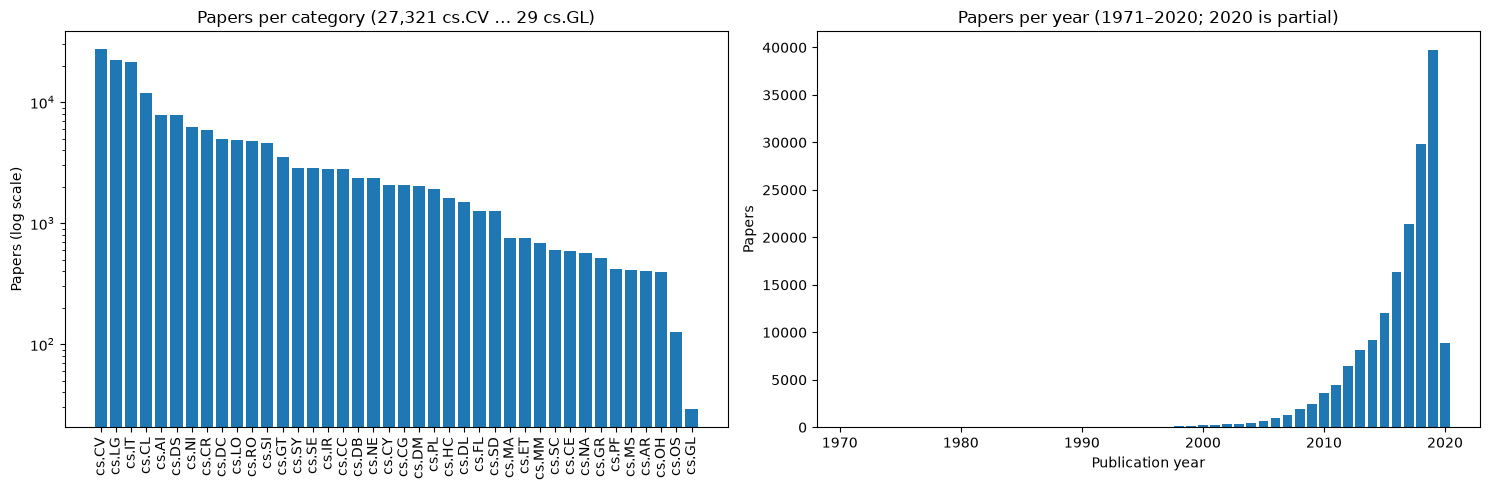

In [ ]:
cats = paper["cat"].map(lambda c: "cs." + c.split()[-1].upper()).value_counts()
years = paper["pub_year"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(cats.index, cats.values, width=0.8)
axes[0].set_yscale("log")
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_ylabel("Papers (log scale)")
axes[0].set_title(f"Papers per category ({cats.max():,} {cats.idxmax()} … {cats.min():,} {cats.idxmin()})")
axes[1].bar(years.index, years.values, width=0.8)
axes[1].set_xlabel("Publication year")
axes[1].set_ylabel("Papers")
axes[1].set_title(f"Papers per year ({years.index.min()}–{years.index.max()}; {years.index.max()} is partial)")
plt.tight_layout()
plt.show()

## 2.4 Citation graph
Directed graph, citing → cited, for PageRank; undirected graph for Louvain and bridge shares. Nodes are keyed by `node_id`; `paper_id`, `category` and `pub_year` are node attributes.

In [ ]:
G = nx.DiGraph()

G.add_nodes_from(
    (
        nid, 
        {
            "paper_id": pid, 
            "category": cat,
            "pub_year": year
        }
    )
    for nid, pid, cat, year in zip(paper["node_id"], paper["paper_id"], paper["cat"], paper["pub_year"])
)

G.add_edges_from(edges[["source_node", "target_node"]].itertuples(index=False, name=None))
assert (G.number_of_nodes(), G.number_of_edges()) == (169343, 1166243)  # edges keyed by node_id, nothing dropped


In [ ]:
UG = G.to_undirected()
nodes = list(UG.nodes)  # fixes the row order of every per-paper array below and of every saved file
labels = np.array([UG.nodes[n]["category"] for n in nodes])  # e.g. "arxiv cs lg"
CATEGORY = ["cs." + l.split()[-1].upper() for l in labels]  # display names, e.g. "cs.LG"
y_shuf = np.random.default_rng(42).permutation(labels)  # chance-level baseline: same category sizes, random papers

### Degree distribution

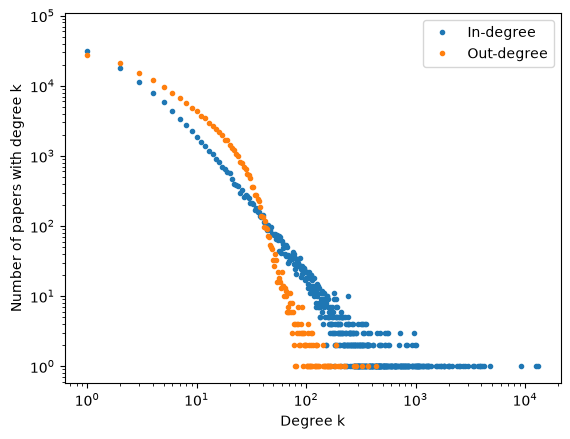

In [ ]:
for deg, name in [(G.in_degree(), "In"), (G.out_degree(), "Out")]:
    counts = Counter(d for _, d in deg)
    k, n = zip(*sorted(counts.items()))
    plt.loglog(k, n, ".", label=f"{name}-degree")
plt.xlabel("Degree k")
plt.ylabel("Number of papers with degree k")
plt.legend()
plt.show()

# 3. RQ1 Influence: PageRank vs in-degree
Who is most influential, and does PageRank tell us anything beyond counting citations? PageRank on the directed graph (damping 0.85, NetworkX default).

In [ ]:
page_rank = nx.pagerank(G)

## 3.1 PageRank vs in-degree
In-degree counts citations; PageRank also weighs who cites a paper (a citation from a high-PageRank paper counts more). Are the top papers the same, and is PageRank mostly measuring age?

In [ ]:
# One row per paper: PageRank, in-degree (citations received inside the dataset), year and both ranks
title_of = papers_title_abs.set_index("paper_id")["title"]
influence = pd.DataFrame({
    "pagerank": pd.Series(page_rank),
    "in_degree": pd.Series(dict(G.in_degree())),
    "year": pd.Series(nx.get_node_attributes(G, "pub_year")),
})
influence["title"] = [title_of[int(G.nodes[n]["paper_id"])] for n in influence.index]
influence["pagerank_rank"] = influence["pagerank"].rank(ascending=False, method="first").astype(int)
influence["in_degree_rank"] = influence["in_degree"].rank(ascending=False, method="first").astype(int)  # ties: arbitrary order
influence["cat"] = CATEGORY
cited = influence["in_degree"] > 0  # uncited papers all get the same minimum PageRank, which inflates the correlation
top_pr = set(influence.index[influence["pagerank_rank"] <= 100])
top_in = set(influence.index[influence["in_degree_rank"] <= 100])
print(f"Spearman PageRank vs in-degree: {spearmanr(influence['pagerank'], influence['in_degree']).statistic:.3f} (all papers), "
      f"{spearmanr(influence.loc[cited, 'pagerank'], influence.loc[cited, 'in_degree']).statistic:.3f} "
      f"({cited.sum():,} cited papers)")
print(f"Top-100 overlap: {len(top_pr & top_in)} papers in both, Jaccard {len(top_pr & top_in) / len(top_pr | top_in):.2f}")

Spearman PageRank vs in-degree: 0.925 (all papers), 0.716 (107,337 cited papers)
Top-100 overlap: 36 papers in both, Jaccard 0.22


In [ ]:
# Top 10 by PageRank and top 10 by citations, each with its rank on the other measure
cols = ["title", "year", "pagerank_rank", "in_degree", "in_degree_rank", "cat"]
with pd.option_context("display.max_colwidth", 80):
    display(influence.nsmallest(10, "pagerank_rank")[cols])
    display(influence.nsmallest(10, "in_degree_rank")[cols])

,title,year,pagerank_rank,in_degree,in_degree_rank,cat
88803,improving neural networks by preventing co adaptation of feature detectors,2012,1,808,84,cs.NE
159030,deep big simple neural nets for handwritten digit recognition,2010,2,93,1557,cs.NE
125272,rich feature hierarchies for accurate object detection and semantic segmenta...,2013,3,2493,16,cs.CV
14201,decaf a deep convolutional activation feature for generic visual recognition,2013,4,830,77,cs.CV
1353,adam a method for stochastic optimization,2014,5,13155,1,cs.LG
46132,visualizing and understanding convolutional networks,2013,6,1828,23,cs.CV
25208,very deep convolutional networks for large scale image recognition,2014,7,9244,3,cs.CV
22502,overfeat integrated recognition localization and detection using convolution...,2013,8,836,76,cs.CV
22035,going deeper with convolutions,2014,9,3861,7,cs.CV
98786,caffe convolutional architecture for fast feature embedding,2014,10,2687,14,cs.CV


,title,year,pagerank_rank,in_degree,in_degree_rank,cat
1353,adam a method for stochastic optimization,2014,5,13155,1,cs.LG
67166,deep residual learning for image recognition,2015,16,12527,2,cs.CV
25208,very deep convolutional networks for large scale image recognition,2014,7,9244,3,cs.CV
69794,batch normalization accelerating deep network training by reducing internal ...,2015,21,4779,4,cs.LG
93649,imagenet large scale visual recognition challenge,2014,14,4238,5,cs.CV
115359,neural machine translation by jointly learning to align and translate,2014,25,4033,6,cs.CL
22035,going deeper with convolutions,2014,9,3861,7,cs.CV
133376,faster r cnn towards real time object detection with region proposal networks,2015,58,3844,8,cs.CV
106699,distributed representations of words and phrases and their compositionality,2013,20,3737,9,cs.CL
166425,fully convolutional networks for semantic segmentation,2014,28,3407,10,cs.CV


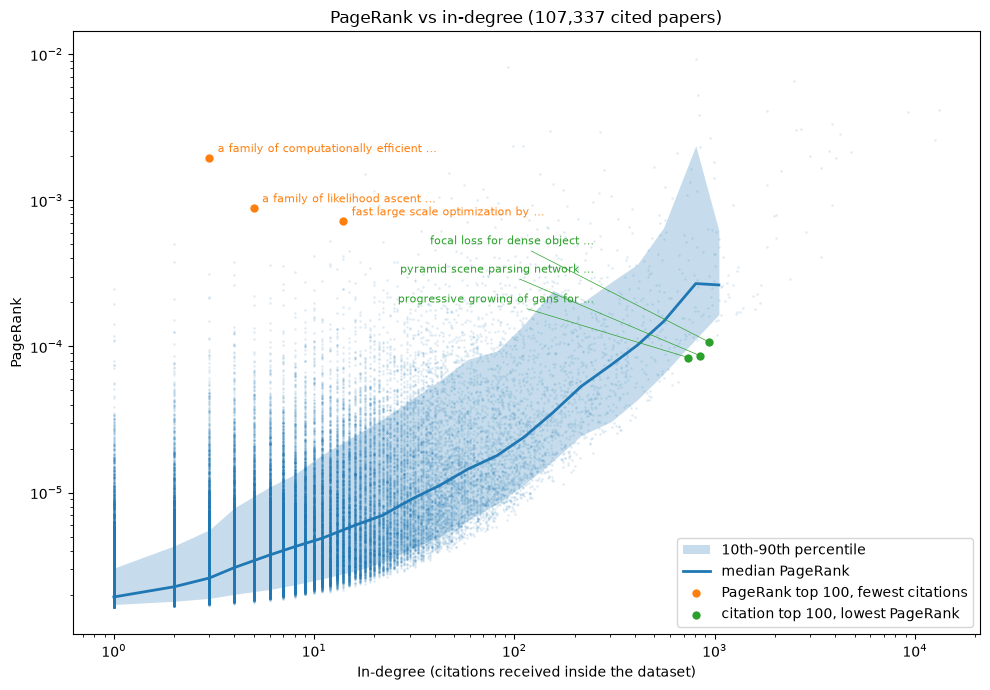

,title,year,pagerank_rank,in_degree,in_degree_rank,cat
140314,a family of computationally efficient and simple estimators for unnormalized...,2012,24,3,56488,cs.LG
38619,a family of likelihood ascent search multiuser detectors an upper bound of b...,2009,60,5,34694,cs.IT
59487,fast large scale optimization by unifying stochastic gradient and quasi newt...,2013,74,14,13894,cs.LG
34873,progressive growing of gans for improved quality stability and variation,2017,1140,740,95,cs.NE
121343,pyramid scene parsing network,2016,1098,847,74,cs.CV
38853,focal loss for dense object detection,2017,837,937,66,cs.CV


In [ ]:
# Log-log scatter for cited papers (in-degree 0 cannot be shown on a log axis). 
# Labelled: the 3 PageRank top-100 papers with the fewest citations, and the 3 citation top-100 papers with the lowest PageRank.
outliers = pd.concat([influence.loc[list(top_pr)].nsmallest(3, "in_degree"),
                      influence.loc[list(top_in)].nlargest(3, "pagerank_rank")])
c = influence[cited]
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(c["in_degree"], c["pagerank"], s=3, alpha=0.15, linewidths=0, rasterized=True)
# The band: median and 10-90% range of PageRank within log-spaced in-degree bins (bins with >= 20 papers)
bins = pd.cut(c["in_degree"], np.logspace(0, np.log10(c["in_degree"].max() + 1), 30), right=False)
band = c.groupby(bins, observed=True).agg(x=("in_degree", "median"), n=("pagerank", "size"),
                                          lo=("pagerank", lambda v: v.quantile(0.1)), mid=("pagerank", "median"),
                                          hi=("pagerank", lambda v: v.quantile(0.9)))
band = band[band["n"] >= 20]
ax.fill_between(band["x"], band["lo"], band["hi"], color="tab:blue", alpha=0.25, linewidth=0, label="10th-90th percentile")
ax.plot(band["x"], band["mid"], color="tab:blue", linewidth=2, label="median PageRank")
HIGH_PR, HIGH_CIT = "tab:orange", "tab:green"
for part, color, label in [(outliers.iloc[:3], HIGH_PR, "PageRank top 100, fewest citations"),
                           (outliers.iloc[3:], HIGH_CIT, "citation top 100, lowest PageRank")]:
    ax.scatter(part["in_degree"], part["pagerank"], s=64, color=color, edgecolors="white", linewidths=2, zorder=3,
               label=label)
for _, r in outliers.iloc[:3].iterrows():  # high PageRank, few citations: label to the right
    ax.annotate(" ".join(r["title"].split()[:5]) + " …", (r["in_degree"], r["pagerank"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8, color=HIGH_PR)
# many citations, low PageRank: the points sit close together, so place the labels above them, highest point first
for y_text, (_, r) in zip([5e-4, 3.2e-4, 2e-4], outliers.iloc[3:].sort_values("pagerank", ascending=False).iterrows()):
    ax.annotate(" ".join(r["title"].split()[:5]) + " …", (r["in_degree"], r["pagerank"]), xytext=(250, y_text),
                textcoords="data", fontsize=8, ha="right", color=HIGH_CIT,
                arrowprops=dict(arrowstyle="-", linewidth=0.5, color=HIGH_CIT))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("In-degree (citations received inside the dataset)")
ax.set_ylabel("PageRank")
ax.set_title(f"PageRank vs in-degree ({len(c):,} cited papers)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
with pd.option_context("display.max_colwidth", 80):
    display(outliers[cols])

In [ ]:
G.in_degree(list(outliers.index)), G.out_degree(list(outliers.index))

(InDegreeView({'140314': 3, '38619': 5, '59487': 14, '34873': 740, '121343': 847, '38853': 937}),
 OutDegreeView({'140314': 0, '38619': 1, '59487': 5, '34873': 22, '121343': 30, '38853': 26}))

In [ ]:
targets = list(outliers.index[:3]) + list(influence.index[influence["pagerank_rank"] == 2])
chain = pd.DataFrame([{"paper": influence.at[n, "title"][:50], "paper_rank": influence.at[n, "pagerank_rank"],
                       "citations": influence.at[n, "in_degree"], "citer": influence.at[u, "title"][:50],
                       "citer_rank": influence.at[u, "pagerank_rank"], "citer_cites": G.out_degree(u),
                       "share_passed": 1 / G.out_degree(u)}
                      for n in targets for u in G.predecessors(n)])
chain.sort_values(["paper_rank", "citer_rank"]).groupby("paper_rank").head(3).set_index(["paper_rank", "paper", "citations"]).round(2)

citer  \
paper_rank paper                                              citations                                                      
2          deep big simple neural nets for handwritten digit  93         improving neural networks by preventing co ada...   
                                                              93         building high level features using large scale...   
                                                              93         representation learning a review and new persp...   
24         a family of computationally efficient and simple e 3          a fast and simple algorithm for training neura...   
                                                              3          bregman divergence as general framework to est...   
                                                              3          general probabilistic surface optimization and...   
60         a family of likelihood ascent search multiuser det 5          scaling up mimo opportunities and challenges w...   
                                                              5          a family of likelihood ascent search multiuser...   
                                                              5          massive mimo and waveform design for 5th gener...   
74         fast large scale optimization by unifying stochast 14                 adam a method for stochastic optimization   
                                                              14         identifying and attacking the saddle point pro...   
                                                              14         deep unsupervised learning using nonequilibriu...   

                                                                         citer_rank  \
paper_rank paper                                              citations               
2          deep big simple neural nets for handwritten digit  93                  1   
                                                              93                 13   
                                                              93                 15   
24         a family of computationally efficient and simple e 3                  18   
                                                              3               67838   
                                                              3               99559   
60         a family of likelihood ascent search multiuser det 5                  89   
                                                              5                 115   
                                                              5               41693   
74         fast large scale optimization by unifying stochast 14                  5   
                                                              14                392   
                                                              14                734   

                                                                         citer_cites  \
paper_rank paper                                              citations                
2          deep big simple neural nets for handwritten digit  93                   1   
                                                              93                   2   
                                                              93                  23   
24         a family of computationally efficient and simple e 3                    1   
                                                              3                    3   
                                                              3                   34   
60         a family of likelihood ascent search multiuser det 5                    1   
                                                              5                    1   
                                                              5                   14   
74         fast large scale optimization by unifying stochast 14                   6   
                                                              14             

In [ ]:
# Top-100 highest cited papers with the smallest PageRank
high_cite_low_pr = influence.loc[list(top_in)].nlargest(5, "pagerank_rank")
e = edges[edges["target_node"].isin(high_cite_low_pr.index)].copy()
for side, col in [("paper", "target_node"), ("citer", "source_node")]:
    info = influence.loc[e[col]]
    e[f"{side}_year"] = info["year"].to_numpy()
    e[f"{side}_rank"] = info["pagerank_rank"].to_numpy()
    e[f"{side}_citations"] = info["in_degree"].to_numpy()
e["citer_cites"] = [G.out_degree(u) for u in e["source_node"]]
e.describe()
# e.sort_values(["paper_rank", "citer_rank"]).set_index(["paper_rank", "paper_citations", "paper_year", "target_node"])

,paper_year,paper_rank,paper_citations,citer_year,citer_rank,citer_citations,citer_cites
count,4117.000000,4117.000000,4117.000000,4117.000000,4117.000000,4117.000000,4117.000000
mean,2016.407335,923.254554,828.895555,2018.658732,98060.407335,11.314064,26.438912
std,0.491398,156.274363,68.483509,0.781143,40800.093983,50.520923,20.710297
min,2016.000000,764.000000,740.000000,2016.000000,443.000000,0.000000,1.000000
25%,2016.000000,796.000000,777.000000,2018.000000,69529.000000,0.000000,16.000000
50%,2016.000000,837.000000,816.000000,2019.000000,101331.000000,1.000000,24.000000
75%,2017.000000,1098.000000,847.000000,2019.000000,128631.000000,6.000000,32.000000
max,2017.000000,1140.000000,937.000000,2020.000000,169342.000000,1582.000000,322.000000


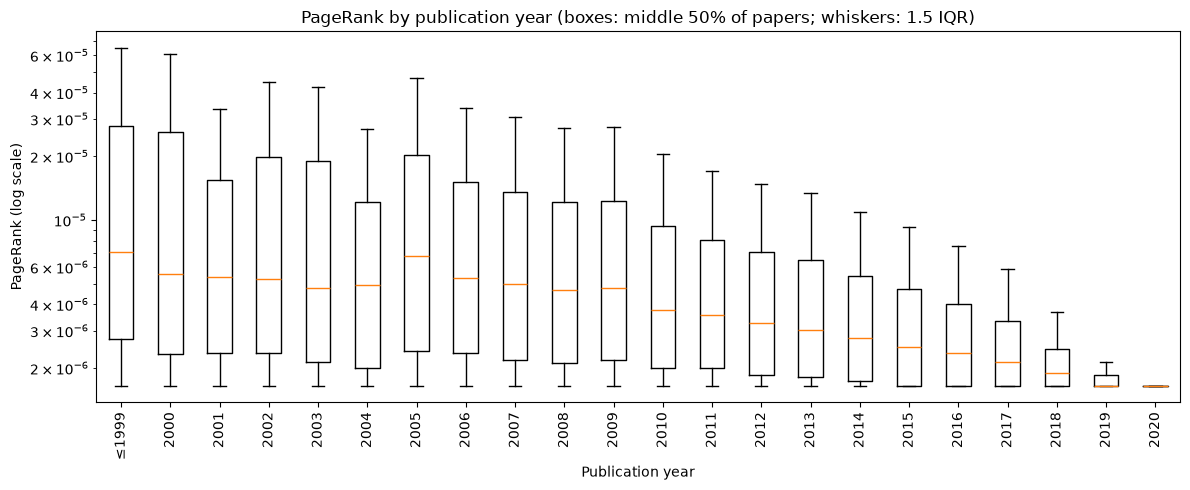

Spearman with year: PageRank -0.496, in-degree -0.354
median year: all papers 2017, PageRank top 100 2012, citation top 100 2015
Spearman of within-year ranks (cited papers): 0.864


In [ ]:
# Age bias: PageRank by publication year
by_year = influence.assign(year_group=influence["year"].clip(lower=1999))
groups = sorted(by_year["year_group"].unique())
fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot([by_year.loc[by_year["year_group"] == y, "pagerank"] for y in groups], showfliers=False)
ax.set_xticks(range(1, len(groups) + 1), ["≤1999" if y == 1999 else str(y) for y in groups], rotation=90)
ax.set_yscale("log")
ax.set_xlabel("Publication year")
ax.set_ylabel("PageRank (log scale)")
ax.set_title("PageRank by publication year (boxes: middle 50% of papers; whiskers: 1.5 IQR)")
plt.tight_layout()
plt.show()

print(f"Spearman with year: PageRank {spearmanr(influence['year'], influence['pagerank']).statistic:.3f}, "
      f"in-degree {spearmanr(influence['year'], influence['in_degree']).statistic:.3f}")
print(f"median year: all papers {influence['year'].median():.0f}, PageRank top 100 "
      f"{influence.loc[list(top_pr), 'year'].median():.0f}, citation top 100 {influence.loc[list(top_in), 'year'].median():.0f}")
# Within-year comparison: is a paper's PageRank rank among papers of the same year close to its citation rank there?
within = influence.groupby("year")[["pagerank", "in_degree"]].rank(ascending=False)
print(f"Spearman of within-year ranks (cited papers): "
      f"{spearmanr(within.loc[cited, 'pagerank'], within.loc[cited, 'in_degree']).statistic:.3f}")

**Finding: PageRank and in-degree agree broadly but not at the top, and PageRank favours older papers more than citation counts do.**

- **Broad agreement.** Spearman correlation 0.925 over all papers, but 0.716 over the 107,337 cited papers. The 62,006 uncited papers all share the minimum PageRank, which inflates the first number.
- **Different top papers.** Only 36 papers are in both top-100 lists (Jaccard 0.22). The most-cited paper, Adam (13,155 citations), is 5th by PageRank. Dropout (*Improving neural networks by preventing co-adaptation…*) is 1st by PageRank but 84th by citations, and *Deep big simple neural nets for handwritten digit recognition* is 2nd by PageRank with only 93 citations (rank 1,557).
- **Why they differ.** PageRank flows along chains of papers with short reference lists inside the dataset. Dropout's only in-dataset citation is *Deep big simple neural nets*, so that paper receives all of dropout's PageRank. The paper ranked 24th has just 3 citations, but one is from the 18th-ranked paper, whose only in-dataset citation it is. Because the dataset keeps only citations between arXiv CS papers, many reference lists are short, which makes this effect stronger.
- **Recent, highly cited papers rank low.** *Focal loss* (937 citations, PageRank rank 837), *Pyramid scene parsing network* and *Progressive growing of GANs* are cited mostly by recent papers, which have little PageRank to pass on.
- **Age bias.** PageRank falls with publication year more strongly than citations do (Spearman with year −0.496 vs −0.354). The median year is 2012 for the PageRank top 100, 2015 for the citation top 100 and 2017 for all papers. So PageRank is partly measuring age, but not mostly: within the same publication year, PageRank ranks and citation ranks agree closely (Spearman 0.864).

# 4. RQ2 Alignment: Louvain communities vs categories
How closely do the communities formed by citations match the 40 arXiv categories? Louvain on the undirected graph. First choose γ on the raw Louvain partitions, then choose the minimum community size at that γ, then fix the final partition and compare it with the categories.

In [ ]:
def merge_small(UG, comms, min_size):
    groups = dict(enumerate(map(set, sorted(comms, key=len, reverse=True))))
    node_c = {n: i for i, c in groups.items() for n in c}
    for i in sorted(groups, key=lambda i: len(groups[i])):  # smallest first; a merged group can merge again
        if len(groups[i]) >= min_size:
            continue
        links = Counter(node_c[v] for u in groups[i] for v in UG[u] if node_c[v] != i)
        if not links:  # no outside neighbour: only on a disconnected graph (section 6), so keep it as it is
            continue
        j = max(links.items(), key=lambda kv: (kv[1], -kv[0]))[0]  # most shared edges, ties -> lowest id
        for n in groups[i]:
            node_c[n] = j
        groups[j] |= groups.pop(i)
    return sorted(groups.values(), key=len, reverse=True)

## 4.1 Step 1: choose resolution (resolution sweep on raw Louvain partitions)

In [ ]:
GAMMAS = [0.25, 0.5, 1, 2, 4]
SEEDS = [int(i) for i in range(42, 48)]
sweep, rows = {}, []
for g in GAMMAS:
    preds = []
    for s in SEEDS:
        raw = louvain_communities(UG, resolution=g, seed=s, weight=None)
        sweep[g, s] = raw
        node_c = {n: i for i, c in enumerate(raw) for n in c}
        preds.append([node_c[n] for n in nodes])
        rows.append({
            "gamma": g, "seed": s,
            "communities": len(raw),
            "modularity": nx.community.modularity(UG, raw, weight=None),
            "NMI": normalized_mutual_info_score(labels, preds[-1]),
            "ARI": adjusted_rand_score(labels, preds[-1]),
        })
    stab = [adjusted_rand_score(a, b) for a, b in combinations(preds, 2)]
    for r in rows[-len(SEEDS):]:
        r["seed_ARI_mean"], r["seed_ARI_sd"] = np.mean(stab), np.std(stab)

sweep_df = pd.DataFrame(rows)
sweep_summary = sweep_df.groupby("gamma").agg(
    communities=("communities", "mean"),
    modularity=("modularity", "mean"),
    seed_ARI_mean=("seed_ARI_mean", "first"),
    seed_ARI_sd=("seed_ARI_sd", "first"),
    NMI_mean=("NMI", "mean"),
    NMI_sd=("NMI", "std"),
    ARI_mean=("ARI", "mean"),
)
sweep_summary.round(3)

,communities,modularity,seed_ARI_mean,seed_ARI_sd,NMI_mean,NMI_sd,ARI_mean
gamma,,,,,,,
0.25,150.167,0.515,0.584,0.099,0.335,0.020,0.231
0.50,133.833,0.668,0.718,0.026,0.385,0.008,0.324
1.00,142.167,0.705,0.650,0.047,0.397,0.005,0.249
2.00,172.667,0.691,0.637,0.033,0.393,0.003,0.170
4.00,218.500,0.655,0.623,0.025,0.387,0.001,0.100


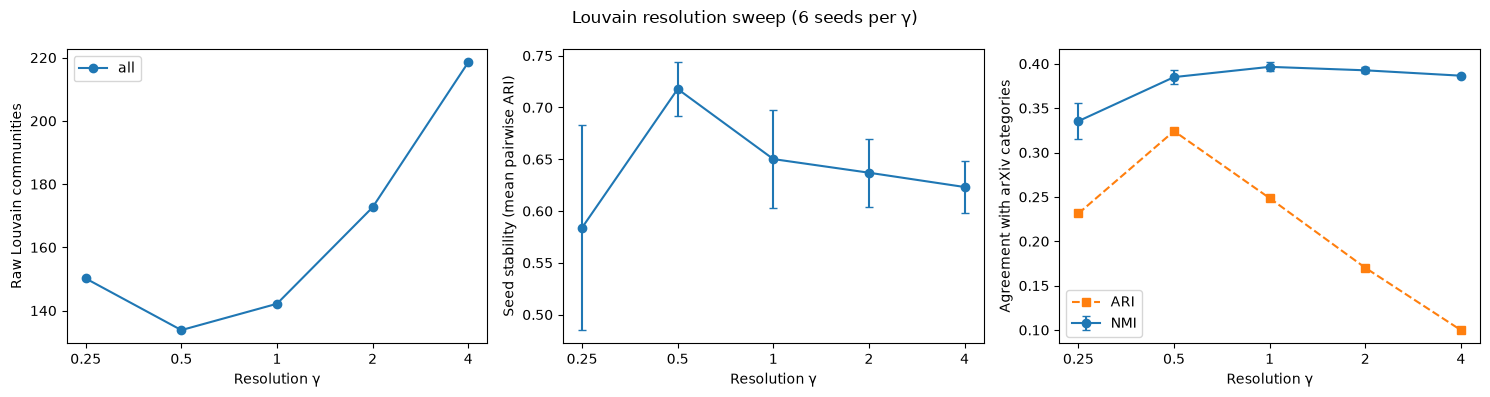

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
s = sweep_summary
axes[0].plot(s.index, s["communities"], "o-")
axes[0].set_ylabel("Raw Louvain communities")
axes[1].errorbar(s.index, s["seed_ARI_mean"], yerr=s["seed_ARI_sd"], fmt="o-", capsize=3)
axes[1].set_ylabel("Seed stability (mean pairwise ARI)")
axes[2].errorbar(s.index, s["NMI_mean"], yerr=s["NMI_sd"], fmt="o-", capsize=3, label="NMI")
axes[2].plot(s.index, s["ARI_mean"], "s--", label="ARI")
axes[2].set_ylabel("Agreement with arXiv categories")
axes[2].legend()
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(GAMMAS, [str(g) for g in GAMMAS])
    ax.set_xlabel("Resolution γ")
fig.suptitle(f"Louvain resolution sweep ({len(SEEDS)} seeds per γ)")
plt.tight_layout()
plt.show()

## 4.2 Step 2: choose MIN_SIZE (at the chosen γ, seed 42)

In [ ]:
# Sensitivity of MIN_SIZE: how many communities remain after merging, how much of the graph was already in
# communities >= MIN_SIZE before merging, and whether merging changes agreement with the arXiv labels.

GAMMA = 1 
raw_communities = sweep[GAMMA, 42]
rows = []
for m in np.arange(0, 550, 50):
    m = int(m)
    comms = merge_small(UG, raw_communities, m)
    comm = {n: i for i, c in enumerate(comms) for n in c}
    pred = [comm[n] for n in nodes]
    rows.append({
        "min_size": m,
        "communities": len(comms),
        "coverage_before_merge": sum(len(c) for c in raw_communities if len(c) >= m) / len(nodes),
        "NMI": normalized_mutual_info_score(labels, pred),
        "ARI": adjusted_rand_score(labels, pred),
    })
pd.DataFrame(rows).set_index("min_size").round(3)

,communities,coverage_before_merge,NMI,ARI
min_size,,,,
0,134,1.000,0.388,0.230
50,42,0.992,0.385,0.231
100,36,0.990,0.385,0.231
150,34,0.989,0.384,0.230
200,34,0.989,0.384,0.230
250,32,0.986,0.382,0.230
300,30,0.983,0.381,0.229
350,30,0.983,0.381,0.229
400,29,0.980,0.380,0.228


## 4.3 Final partition (chosen γ, seed 42, MIN_SIZE = 50)

In [ ]:
MIN_SIZE = 50
communities = louvain_communities(UG, weight="None", resolution=1, seed=42)
communities = merge_small(UG, communities, MIN_SIZE)
assert sum(map(len, communities)) == UG.number_of_nodes() and min(map(len, communities)) >= MIN_SIZE
node_comm = {n: i for i, c in enumerate(communities) for n in c}
louvain_pred = [node_comm[n] for n in nodes]

print(f"{len(raw_communities)} communities -> {len(communities)} after merging those < {MIN_SIZE} papers; "
      f"modularity {nx.community.modularity(UG, communities, weight=None):.3f}")

134 communities -> 42 after merging those < 50 papers; modularity 0.701


## 4.4 Agreement with the categories: NMI, ARI and purity
Each score against the real categories and against shuffled categories (same category sizes, assigned to random papers). The shuffled row is the chance level: NMI is not adjusted for chance, so it shows NMI's floor for this partition; ARI is (expected 0).

In [ ]:
# purity:         share of papers that belong to their group's main category. Rewards many small groups
#                 (one paper per group gives 1), so it is shown together with
# inverse purity: share of papers that belong to their category's main group. Rewards few large groups.
def purity(group, truth):
    return pd.crosstab(np.asarray(group), np.asarray(truth)).max(axis=1).sum() / len(group)

def agreement(group):
    """NMI, ARI, purity and inverse purity of a partition (one group id per paper in `nodes` order)."""
    return pd.DataFrame({lab_name: {"NMI": normalized_mutual_info_score(lab, group),
                                    "ARI": adjusted_rand_score(lab, group),
                                    "purity": purity(group, lab),
                                    "inverse purity": purity(lab, group)}
                         for lab_name, lab in [("arXiv categories", labels), ("shuffled", y_shuf)]}).T

agreement(louvain_pred).round(3)

,NMI,ARI,purity,inverse purity
arXiv categories,0.385,0.231,0.480,0.436
shuffled,0.002,0.000,0.162,0.091


## 4.5 Conductance: communities vs categories
Conductance of a group: links leaving it / min(sum of degrees inside it, sum of degrees outside it). 0 means no links leave the group; random groups score close to 1. If categories have much higher conductance than the communities, citations cut across the official boundaries. Baseline: random partitions with the same group sizes.

In [ ]:
node_idx = {n: i for i, n in enumerate(nodes)}
eu, ev = np.array([(node_idx[u], node_idx[v]) for u, v in UG.edges()]).T
deg = np.bincount(eu, minlength=len(nodes)) + np.bincount(ev, minlength=len(nodes))

def conductance(group):
    """Conductance of each group on UG, indexed by group id. group: one group id per paper in `nodes` order."""
    g, ids = pd.factorize(np.asarray(group))
    cross = g[eu] != g[ev]
    cut = np.bincount(g[eu][cross], minlength=len(ids)) + np.bincount(g[ev][cross], minlength=len(ids))
    vol = np.bincount(g, weights=deg, minlength=len(ids))
    return pd.Series(cut / np.minimum(vol, vol.sum() - vol), index=ids)

partitions = {
    "Louvain communities": louvain_pred,
    "arXiv categories": CATEGORY,
    "random, community sizes": np.random.default_rng(42).permutation(louvain_pred),
    "random, category sizes": y_shuf,
}
cond = {name: conductance(p) for name, p in partitions.items()}
pd.DataFrame({name: {"groups": len(c),
                     "median": c.median(),
                     "mean weighted by papers": np.average(c, weights=pd.Series(partitions[name]).value_counts()[c.index]),
                     "min": c.min(),
                     "max": c.max()}
              for name, c in cond.items()}).T.round(3)

,groups,median,mean weighted by papers,min,max
Louvain communities,42.0,0.106,0.182,0.002,0.397
arXiv categories,40.0,0.521,0.399,0.131,0.956
"random, community sizes",42.0,0.991,0.942,0.910,1.000
"random, category sizes",40.0,0.987,0.923,0.842,1.000


In [ ]:
# Conductance of each arXiv category, most closed first (0 = no links leave the category)
pd.DataFrame({"papers": pd.Series(CATEGORY).value_counts(),
              "conductance": cond["arXiv categories"]}).sort_values("conductance").round(2)

,papers,conductance
cs.IT,21406,0.13
cs.DL,1507,0.17
cs.CV,27321,0.21
cs.CL,11814,0.27
cs.SC,597,0.31
cs.GT,3524,0.33
cs.LO,4839,0.37
cs.CG,2076,0.38
cs.DS,7867,0.38
cs.SE,2834,0.41


## 4.6 How communities match the categories
Heatmap of communities × categories, then where each category's papers went (with each category's conductance from 4.5). What each community is made of is in the topic table in 4.7.

In [ ]:
# Compare a partition with the arXiv categories:
#   heatmap:     row-normalised, rows = groups (largest first); categories are ordered by the group holding most
#                of their papers, so groups that match one category line up on the diagonal
#   by_category: where each category's papers went (% of the CATEGORY's papers, e.g. 86% of cs.CL is in C0)
#   by_group:    what each group is made of        (% of the GROUP's papers,    e.g. 66% of C0 is cs.CL)
# The last table column lists entries holding >= SHARE; the rest are smaller and not listed.
SHARE = 0.10

def spread(counts, prefix=""):
    """Entries holding >= SHARE of the row's papers, largest first, e.g. 'C1 45%, C9 20%'."""
    s = (counts / counts.sum()).sort_values(ascending=False)
    return ", ".join(f"{prefix}{k} {v:.0%}" for k, v in s[s >= SHARE].items())

def pct(x):
    return (100 * x).round().astype(int)

def compare_to_categories(group, kind, prefix, title):
    """group: one group id per paper in `nodes` order; kind: e.g. 'community'; prefix: label prefix, e.g. 'C'."""
    ct = pd.crosstab(pd.Series(group, name=kind), pd.Series(CATEGORY, name="category"))
    ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False, kind="stable").index]  # largest group first
    ct.index = [f"{prefix}{g}" for g in ct.index]
    ct.index.name = kind

    order = ct.idxmax().map(ct.index.get_loc).sort_values(kind="stable").index
    fig, ax = plt.subplots(figsize=(14, 12))
    im = ax.imshow(ct[order].div(ct.sum(axis=1), axis=0), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(order)), order, rotation=90)
    ax.set_yticks(range(len(ct)), [f"{g}  (n={n:,})" for g, n in ct.sum(axis=1).items()])
    ax.set_xlabel("arXiv category")
    ax.set_ylabel(f"{title} {kind} (all {len(ct)}, largest first)")
    ax.set_title(f"{title}: share of each {kind}'s papers by arXiv category")
    fig.colorbar(im, ax=ax, label=f"Share of the {kind}'s papers")
    plt.tight_layout()
    plt.show()

    cat_share = ct.T.div(ct.T.sum(axis=1), axis=0)
    by_category = pd.DataFrame({
        "papers in category": ct.T.sum(axis=1),
        f"main {kind}": cat_share.idxmax(axis=1),
        f"% of category in main {kind}": pct(cat_share.max(axis=1)),
        f"% of category in each {kind}": ct.T.apply(spread, axis=1),
    }).sort_values("papers in category", ascending=False)

    group_share = ct.div(ct.sum(axis=1), axis=0)
    by_group = pd.DataFrame({
        f"papers in {kind}": ct.sum(axis=1),
        "main category": group_share.idxmax(axis=1),
        f"% of {kind} from main category": pct(group_share.max(axis=1)),
        f"% of {kind} from each category": ct.apply(spread, axis=1),
    })
    return by_category, by_group

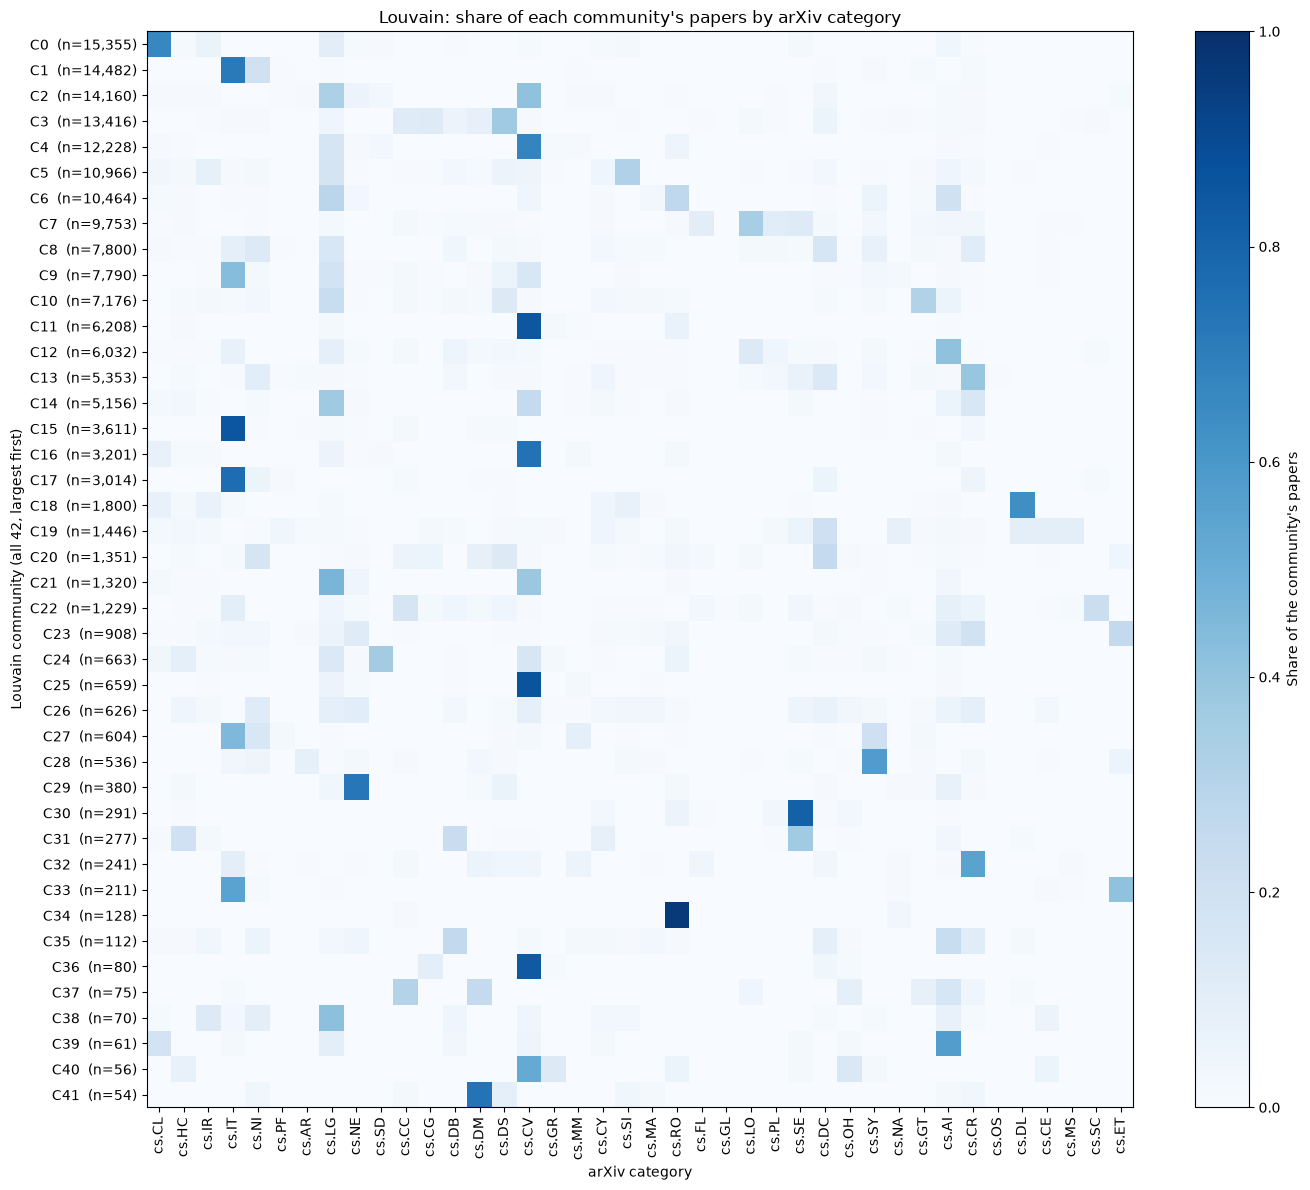

In [ ]:
by_category, by_community = compare_to_categories(louvain_pred, "community", "C", "Louvain")

In [ ]:
# Where each category's papers went (largest category first). % = share of the CATEGORY's papers.
with pd.option_context("display.max_colwidth", None):
    display(by_category.assign(conductance=cond["arXiv categories"].round(2)))

,papers in category,main community,% of category in main community,% of category in each community,conductance
category,,,,,
cs.CV,27321,C4,30,"C4 30%, C2 21%, C11 19%",0.21
cs.LG,22187,C2,21,"C2 21%, C6 13%",0.48
cs.IT,21406,C1,48,"C1 48%, C9 16%, C15 14%, C17 11%",0.13
cs.CL,11814,C0,86,C0 86%,0.27
cs.AI,7869,C12,31,"C12 31%, C6 26%",0.64
cs.DS,7867,C3,63,"C3 63%, C10 12%",0.38
cs.NI,6232,C1,46,"C1 46%, C8 17%",0.52
cs.CR,5862,C13,36,"C13 36%, C8 15%, C14 13%",0.49
cs.DC,4958,C8,25,"C8 25%, C13 15%, C3 14%",0.59


## 4.7 What communities are grouped by (topics vs techniques)
Top phrases per community from class-based TF-IDF on titles and abstracts (description only, not a clustering method).

In [ ]:
def to_ascii(text):
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()

In [ ]:
papers_by_id = papers_title_abs.set_index("paper_id")
node_text = {}
for node_id in nodes:
    p = papers_by_id.loc[int(G.nodes[node_id]["paper_id"])]
    node_text[node_id] = to_ascii(p["title"] + " " + p["abstract"])

In [ ]:
# Class-based TF-IDF (as in BERTopic): one document per cluster, score = word share in the cluster
# * log(1 + avg cluster length / word's total count). Plain TF-IDF over a few dozen cluster-documents
# ranks words found in only one cluster (dataset names, acronyms) above the cluster's main topic words.

stop_words = list(ENGLISH_STOP_WORDS | {"method", "methods", "based", "approach", "propose", "proposed",
                                        "paper", "results", "art", "state", "show", "using", "use"})

def fit_topics(node_cluster):
    """c-TF-IDF over the clusters in node_cluster ({node_id: cluster id}); returns top_words(cluster, n)."""
    cluster_corpus = defaultdict(list)
    for node_id in nodes:
        cluster_corpus[node_cluster[node_id]].append(node_text[node_id])
    cluster_ids = sorted(cluster_corpus)
    # All 2-3 word n-grams over the full corpus is ~19M terms, and CountVectorizer.fit holds them all in memory
    # (~5 GB) before any pruning. So pick the vocabulary from a sample of papers, then count only those n-grams
    # (exactly, over every paper) per cluster. The sample is stratified: up to 1000 papers per cluster, so small
    # clusters are included whole. A uniform 20k sample missed most top phrases of small clusters.
    # Checked with arXiv labels as clusters: 96% of the exact top-15 recovered (worst cluster 80%); ~1.7 GB peak.
    rng = random.Random(42)
    sample = [doc for k in cluster_ids
              for doc in (cluster_corpus[k] if len(cluster_corpus[k]) <= 1000 else rng.sample(cluster_corpus[k], 1000))]
    vocab = CountVectorizer(stop_words=stop_words, ngram_range=(2, 3)).fit(sample).vocabulary_
    vectorizer = CountVectorizer(stop_words=stop_words, ngram_range=(2, 3), vocabulary=vocab)
    word_counts = vectorizer.fit_transform(" ".join(cluster_corpus[k]) for k in cluster_ids)
    vocab = vectorizer.get_feature_names_out()
    tf = word_counts.multiply(1 / word_counts.sum(axis=1)).tocsr()
    idf = np.log(1 + word_counts.sum() / word_counts.shape[0] / np.asarray(word_counts.sum(axis=0)).ravel())
    ctfidf = tf.multiply(idf).tocsr()

    def top_words(cluster, n=10):
        row = ctfidf[cluster_ids.index(cluster)]
        top = np.argsort(row.data)[::-1][:n]
        return pd.Series(row.data[top], index=vocab[row.indices[top]])
    return top_words

def topic_table(by_group, top_words, kind, group):
    """by_group (from compare_to_categories) plus each group's median degree and top 8 phrases.
    group: one group id per paper in `nodes` order. Groups are labelled like 'C3'."""
    degree = pd.Series([UG.degree(n) for n in nodes]).groupby(np.asarray(group)).median()  # undirected degree
    ids = [int(g[1:]) for g in by_group.index]
    return by_group[[f"papers in {kind}", f"% of {kind} from each category"]].assign(
        median_degree=degree.loc[ids].values,
        top_phrases=[", ".join(top_words(i, 8).index) for i in ids])



In [ ]:
top_words = fit_topics(node_comm)

In [ ]:
community_topics = topic_table(by_community, top_words, "community", louvain_pred)
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(community_topics)

,papers in community,% of community from each category,median_degree,top_phrases
community,,,,
C0,15355,"cs.CL 66%, cs.LG 10%",10.0,"natural language, machine translation, neural network, word embeddings, neural machine, recurrent neural, neural machine translation, neural networks"
C1,14482,"cs.IT 71%, cs.NI 20%",7.0,"multiple access, massive mimo, base station, wireless networks, channel information, power allocation, cellular networks, multiple input"
C2,14160,"cs.CV 41%, cs.LG 33%",10.0,"neural networks, neural network, deep learning, convolutional neural, deep neural, convolutional neural networks, deep neural networks, machine learning"
C3,13416,"cs.DS 37%, cs.CG 12%, cs.CC 12%",5.0,"polynomial time, log log, et al, time algorithm, lower bound, lower bounds, running time, data structure"
C4,12228,"cs.CV 67%, cs.LG 17%",13.0,"generative adversarial, deep learning, semantic segmentation, neural network, convolutional neural, adversarial networks, generative adversarial networks, domain adaptation"
C5,10966,"cs.SI 32%, cs.LG 17%",6.0,"social networks, real world, social media, social network, community detection, online social, link prediction, recommender systems"
C6,10464,"cs.LG 28%, cs.RO 27%, cs.AI 20%",7.0,"reinforcement learning, deep reinforcement, deep reinforcement learning, multi agent, real world, learning rl, motion planning, reinforcement learning rl"
C7,9753,"cs.LO 34%, cs.SE 12%, cs.PL 11%, cs.FL 10%",3.0,"model checking, higher order, temporal logic, type theory, lambda calculus, order logic, finite automata, software development"
C8,7800,"cs.DC 16%, cs.LG 16%, cs.NI 13%, cs.CR 12%",4.0,"differential privacy, cloud computing, machine learning, federated learning, differentially private, big data, privacy preserving, internet things"


**Finding: communities are grouped mostly by research problem, finer than the arXiv categories; techniques with their own literature form communities that cut across categories.** (Labels below are our reading of the table above.)

- **Topic (one category, split by sub-problem).**
  - cs.IT splits into C1 wireless systems (massive MIMO, power allocation), C15 information/coding theory (polar codes, rate distortion), C17 coding for storage (network coding, Reed-Solomon) and C9 sparse recovery.
  - cs.CV splits into C11 detection/pose/point clouds, C16 video + language (captioning, VQA), C25 person re-identification and C4 generative models/segmentation.
  - Small niche topics: C27 age of information, C33 molecular communication, C34 parallel robots, C18 scientometrics.
- **Technique (mixes categories).**
  - C6 reinforcement learning (cs.LG 28%, cs.RO 27%, cs.AI 20%)
  - C14 adversarial examples (cs.LG 37%, cs.CV 25%, cs.CR 15%)
  - C21 zero-shot / meta-learning (cs.LG 47%, cs.CV 38%)
  - C9 compressed sensing / low rank (cs.IT 43%, cs.LG 18%, cs.CV 15%)
  - C2 deep neural networks (cs.CV 41%, cs.LG 33%)
- **Mathematical style (merges theory categories).**
  - C3 algorithms and complexity (polynomial time, lower bounds): cs.DS, cs.CG, cs.CC
  - C7 logic and verification (model checking, temporal logic, lambda calculus): cs.LO, cs.SE, cs.PL, cs.FL

This explains the moderate agreement (NMI ≈ 0.39): categories record what a paper is *about*, while citations also follow *how* the work is done.

# 5. RQ3 Bridges: influential papers between communities
Which high-PageRank papers connect different communities, and are the most influential papers connected mainly within their community or across communities? Uses PageRank (section 3) and the final Louvain partition (section 4).

In [ ]:
# For each paper, using its citation links in either direction (UG) and the final Louvain partition:
#   cross_share:   share of its links that go to papers in other communities
#   cross_field_share: share of its links that go to communities with a different main category than its own
#                  community (C2 and C4 are both mainly cs.CV, so a C2-C4 link is cross-community, not cross-field)
#   participation: 1 - sum over communities of (links to that community / all links)^2. 0 when every link stays in
#                  one community; close to 1 when links spread evenly over many communities
# Influential = PageRank top TOP_PR (PageRank on the directed graph). Bridge = influential with cross_share >= BRIDGE_SHARE.
TOP_PR = 100
BRIDGE_SHARE = 0.5
MIN_LINKS = 50  # shares from a handful of links are noise (2 of 3 links = 0.67); tables below skip these papers
main_cat = by_community["main category"]  # e.g. main_cat["C2"] == "cs.CV"

rows = []
for n in nodes:
    links = Counter(node_comm[v] for v in UG[n])
    k = sum(links.values())
    others = sorted(((c, m) for c, m in links.items() if c != node_comm[n]), key=lambda cm: -cm[1])
    rows.append({
        "node_id": n,
        "links": k,
        "cross_share": sum(m for _, m in others) / k,
        "cross_field_share": sum(m for c, m in others if main_cat[f"C{c}"] != main_cat[f"C{node_comm[n]}"]) / k,
        "participation": 1 - sum((m / k) ** 2 for m in links.values()),
        "top linked communities (links)": ", ".join(f"C{c} {main_cat[f'C{c}']} ({m})" for c, m in others[:3]),
    })
paper_links = pd.DataFrame(rows).set_index("node_id")
paper_links["pagerank_rank"] = pd.Series(page_rank).rank(ascending=False, method="first").astype(int)

top = paper_links[paper_links["pagerank_rank"] <= TOP_PR].sort_values("pagerank_rank")
top.insert(0, "title", [papers_by_id.loc[int(G.nodes[n]["paper_id"])]["title"] for n in top.index])
top.insert(1, "year", [G.nodes[n]["pub_year"] for n in top.index])
top.insert(2, "category", ["cs." + G.nodes[n]["category"].split()[-1].upper() for n in top.index])
top.insert(3, "community", [f"C{node_comm[n]} {main_cat[f'C{node_comm[n]}']}" for n in top.index])

for col in ["cross_share", "cross_field_share"]:
    print(f"median {col}: all papers {paper_links[col].median():.2f}, PageRank top {TOP_PR} {top[col].median():.2f}")
print(f"{(top['cross_share'] >= BRIDGE_SHARE).sum()} of the PageRank top {TOP_PR} have >= {BRIDGE_SHARE:.0%} "
      f"of their links in other communities (all papers: {(paper_links['cross_share'] >= BRIDGE_SHARE).mean():.0%})")
print(f"{(top['links'] < MIN_LINKS).sum()} of the PageRank top {TOP_PR} have fewer than {MIN_LINKS} links")
top_reliable = top[top["links"] >= MIN_LINKS]

median cross_share: all papers 0.00, PageRank top 100 0.41
median cross_field_share: all papers 0.00, PageRank top 100 0.17
30 of the PageRank top 100 have >= 50% of their links in other communities (all papers: 10%)
12 of the PageRank top 100 have fewer than 50 links


In [ ]:
# Bridge papers: influential, >= MIN_LINKS links, and at least BRIDGE_SHARE of them in other communities, by PageRank
cols = ["pagerank_rank", "title", "year", "category", "community", "links", "cross_share", "cross_field_share", "participation",
        "top linked communities (links)"]
with pd.option_context("display.max_colwidth", None):
    display(top_reliable[top_reliable["cross_share"] >= BRIDGE_SHARE][cols].head(10).round(2))

,pagerank_rank,title,year,category,community,links,cross_share,cross_field_share,participation,top linked communities (links)
node_id,,,,,,,,,,
125272,3,rich feature hierarchies for accurate object detection and semantic segmentation,2013,cs.CV,C11 cs.CV,2496,0.55,0.10,0.72,"C2 cs.CV (566), C4 cs.CV (321), C16 cs.CV (203)"
14201,4,decaf a deep convolutional activation feature for generic visual recognition,2013,cs.CV,C2 cs.CV,836,0.53,0.19,0.73,"C4 cs.CV (161), C11 cs.CV (63), C16 cs.CV (56)"
1353,5,adam a method for stochastic optimization,2014,cs.LG,C4 cs.CV,13161,0.75,0.48,0.84,"C0 cs.CL (3081), C2 cs.CV (2031), C6 cs.LG (1074)"
46132,6,visualizing and understanding convolutional networks,2013,cs.CV,C14 cs.LG,1832,0.71,0.68,0.78,"C2 cs.CV (603), C4 cs.CV (260), C11 cs.CV (159)"
25208,7,very deep convolutional networks for large scale image recognition,2014,cs.CV,C2 cs.CV,9257,0.61,0.17,0.77,"C4 cs.CV (1913), C11 cs.CV (1283), C16 cs.CV (830)"
22502,8,overfeat integrated recognition localization and detection using convolutional networks,2013,cs.CV,C11 cs.CV,837,0.64,0.08,0.71,"C2 cs.CV (307), C4 cs.CV (130), C16 cs.CV (34)"
98786,10,caffe convolutional architecture for fast feature embedding,2014,cs.CV,C2 cs.CV,2692,0.57,0.15,0.75,"C4 cs.CV (439), C11 cs.CV (393), C16 cs.CV (227)"
93649,14,imagenet large scale visual recognition challenge,2014,cs.CV,C2 cs.CV,4255,0.60,0.19,0.77,"C4 cs.CV (675), C11 cs.CV (658), C16 cs.CV (377)"
58062,15,representation learning a review and new perspectives,2012,cs.LG,C4 cs.CV,969,0.70,0.40,0.83,"C2 cs.CV (228), C0 cs.CL (99), C5 cs.SI (86)"


In [ ]:
# Contrast: influential papers (>= MIN_LINKS links) that stay most inside their own community (lowest cross_share)
with pd.option_context("display.max_colwidth", None):
    display(top_reliable.sort_values("cross_share")[cols].head(10).round(2))

,pagerank_rank,title,year,category,community,links,cross_share,cross_field_share,participation,top linked communities (links)
node_id,,,,,,,,,,
161678,93,a tractable approach to coverage and rate in cellular networks,2011,cs.IT,C1 cs.IT,535,0.01,0.01,0.03,"C8 cs.DC (4), C9 cs.IT (1), C27 cs.IT (1)"
125360,78,gaussian interference channel capacity to within one bit,2007,cs.IT,C1 cs.IT,374,0.02,0.01,0.04,"C15 cs.IT (2), C20 cs.DC (2), C17 cs.IT (1)"
26074,68,mimo broadcast channels with finite rate feedback,2006,cs.IT,C1 cs.IT,209,0.02,0.01,0.04,"C8 cs.DC (2), C15 cs.IT (1), C17 cs.IT (1)"
154444,51,uplink capacity and interference avoidance for two tier femtocell networks,2007,cs.NI,C1 cs.IT,50,0.04,0.00,0.08,C15 cs.IT (2)
116654,89,scaling up mimo opportunities and challenges with very large arrays,2013,cs.IT,C1 cs.IT,571,0.05,0.01,0.10,"C9 cs.IT (26), C8 cs.DC (3), C10 cs.GT (1)"
111307,59,femtocell networks a survey,2008,cs.NI,C1 cs.IT,183,0.07,0.04,0.13,"C8 cs.DC (7), C9 cs.IT (2), C15 cs.IT (1)"
123933,54,bayesian compressive sensing via belief propagation,2008,cs.IT,C9 cs.IT,87,0.07,0.03,0.13,"C12 cs.AI (3), C1 cs.IT (3)"
108538,53,from frequency to meaning vector space models of semantics,2010,cs.CL,C0 cs.CL,264,0.08,0.08,0.14,"C14 cs.LG (4), C5 cs.SI (4), C16 cs.CV (3)"
46136,92,hierarchical cooperation achieves optimal capacity scaling in ad hoc networks,2006,cs.IT,C1 cs.IT,116,0.08,0.03,0.15,"C17 cs.IT (2), C8 cs.DC (2), C27 cs.IT (2)"


**Finding: influential papers link across communities far more than typical papers, but mostly between sub-communities of the same field. Only general-purpose deep-learning methods link different fields.**

- **Across communities, yes.** The median paper has no links outside its community (median cross_share 0.00), while the PageRank top 100 send a median 41% of their links to other communities. 30 of the top 100 have at least half their links outside, vs 10% of all papers.
- **Across fields, much less.** The median cross_field_share of the top 100 is only 0.17. Most bridges hold the computer-vision sub-communities together. ResNet (PageRank rank 16) has 64% of its links in other communities but only 21% in other fields: they go to C4, C11 and C16, which are all mainly cs.CV. VGG, R-CNN, Caffe and ImageNet follow the same pattern.
- **Cross-field bridges are general tools.** Adam (rank 5) links its vision community to NLP (C0, 3,081 links) and reinforcement learning (C6), with 48% of its links in other fields. *Visualizing and understanding convolutional networks* (rank 6, 68% cross-field) and *Representation learning: a review* (rank 15, links to vision, NLP and social networks) are similar. Optimisers, frameworks and reviews are used by many fields, so they are cited from all of them.
- **Influential papers that stay inside.** The wireless and information-theory classics in C1 are cited almost only from their own community: *A tractable approach to coverage and rate in cellular networks* (rank 93, 535 links, 1% outside), *Gaussian interference channel capacity to within one bit*, and the massive-MIMO papers. This matches C1 being a closed field (71% cs.IT).

**Caveat.** 12 of the PageRank top 100 have fewer than 50 links (one has 3) and are left out of the tables. PageRank ranks them highly because they are cited by high-PageRank papers, not because they are cited often; compare with in-degree in the influence analysis.

# 6. Robustness check: citations to a newer paper
Section 2 keeps the 20,903 citations to a newer paper. Here the graph is rebuilt without them and PageRank and the final Louvain run (γ = 1, seed 42, MIN_SIZE = 50) are repeated, to show the conclusions do not depend on that choice.

In [ ]:
# Graph without the citations to a newer paper (gap > 0, from the cleaning checks in section 2)
G_old = nx.DiGraph()
G_old.add_nodes_from(G.nodes(data=True))
G_old.add_edges_from(edges.loc[gap <= 0, ["source_node", "target_node"]].itertuples(index=False, name=None))
UG_old = G_old.to_undirected()
components_old = sorted(map(len, nx.connected_components(UG_old)), reverse=True)

pr_old = pd.Series(nx.pagerank(G_old))
pr_now = pd.Series(page_rank)[pr_old.index]
# Papers cut off from the rest stay in their own small groups (merge_small has nothing to merge them into)
communities_old = merge_small(UG_old, louvain_communities(UG_old, resolution=GAMMA, seed=42, weight=None), MIN_SIZE)
comm_old = {n: i for i, c in enumerate(communities_old) for n in c}
pred_now = louvain_pred
pred_old = [comm_old[n] for n in nodes]

def summary(graph, ug, comms, pred, components):
    return {
        "citations": graph.number_of_edges(),
        "connected components": len(components),
        "papers outside the largest component": sum(components[1:]),
        f"communities with >= {MIN_SIZE} papers": sum(len(c) >= MIN_SIZE for c in comms),
        "modularity": round(nx.community.modularity(ug, comms, weight=None), 3),
        "NMI vs categories": round(normalized_mutual_info_score(labels, pred), 3),
        "ARI vs categories": round(adjusted_rand_score(labels, pred), 3),
    }

newer_check = pd.DataFrame({  # object columns keep counts as integers next to the rounded scores
    "all citations (used)": pd.Series(summary(G, UG, communities, pred_now, [UG.number_of_nodes()]), dtype=object),
    "without citations to a newer paper": pd.Series(summary(G_old, UG_old, communities_old, pred_old, components_old), dtype=object),
})
top100 = lambda pr: set(pr.nlargest(100).index)
print(f"PageRank: Spearman correlation {spearmanr(pr_now, pr_old).statistic:.3f}, "
      f"top-100 overlap {len(top100(pr_now) & top100(pr_old))}/100")
print(f"Louvain: ARI between the two partitions {adjusted_rand_score(pred_now, pred_old):.3f}")
newer_check

PageRank: Spearman correlation 0.984, top-100 overlap 91/100
Louvain: ARI between the two partitions 0.801


,all citations (used),without citations to a newer paper
citations,1166243,1145340
connected components,1,848
papers outside the largest component,0,1106
communities with >= 50 papers,42,44
modularity,0.701,0.7
NMI vs categories,0.385,0.393
ARI vs categories,0.231,0.242


**Finding.** Dropping the citations to a newer paper does not change the conclusions, and it would disconnect papers, so keeping them is the better choice.

- Without them, the graph splits into 848 components, and 1,106 papers are cut off from the main one (715 have no links at all). These papers could not be placed in any real community.
- PageRank barely changes: Spearman correlation 0.984, and 91 of the top 100 papers stay in the top 100.
- Louvain finds almost the same partition (ARI 0.80 between the two): 44 vs 42 communities, modularity 0.700 vs 0.701, NMI 0.393 vs 0.385 and ARI 0.242 vs 0.231 against the categories.

# 7. Saved results
One row per paper with its category and Louvain community (`results/node_assignments.csv`).

In [ ]:
# One row per paper: arXiv category and Louvain community (final partition), in `nodes` order.
assignments = pd.DataFrame({
    "node_id": nodes,
    "paper_id": [G.nodes[n]["paper_id"] for n in nodes],
    "category": labels,
    "louvain": louvain_pred,
}).set_index("node_id")
assignments.to_csv("results/node_assignments.csv")
assignments

,paper_id,category,louvain,kmeans_dfs,kmeans_bfs
node_id,,,,,
0,9657784,arxiv cs cr,14,25,23
1,39886162,arxiv cs dc,17,16,3
2,116214155,arxiv cs it,9,4,19
3,121432379,arxiv cs ni,13,32,18
4,231147053,arxiv cs ro,6,20,5
...,...,...,...,...,...
169338,3011696425,arxiv cs cr,14,25,23
169339,3011708313,arxiv cs lg,2,38,15
169340,3011798063,arxiv cs ai,0,5,6
